# Comptage de mots : comparaison de trois méthodes

Ce notebook implémente et compare :
1. un comptage Python séquentiel ;
2. un pseudo-MapReduce en Python (`map`, `shuffle`, `reduce`) ;
3. Hadoop MapReduce, avec mesure réelle lorsque Hadoop est démarré.

Les mêmes fichiers sont utilisés pour toutes les méthodes. Les fichiers de test sont générés avec `N` lignes, puis agrandis par duplication `m` fois.

In [1]:
%pip install -q pandas matplotlib



[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: /home/omar/Bureau/.venv/bin/python -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
from collections import Counter, defaultdict
from statistics import median
import os
from pathlib import Path
import shutil
import subprocess
import tempfile
import time

import pandas as pd
import matplotlib.pyplot as plt

# Connexion automatique à l'installation Hadoop locale.
HADOOP_HOME = Path.home() / 'hadoop'
if HADOOP_HOME.exists():
    os.environ['HADOOP_HOME'] = str(HADOOP_HOME)
    os.environ['HADOOP_CONF_DIR'] = str(HADOOP_HOME / 'etc/hadoop')
    os.environ['PATH'] = str(HADOOP_HOME / 'bin') + os.pathsep + str(HADOOP_HOME / 'sbin') + os.pathsep + os.environ.get('PATH', '')

DOSSIER = Path('donnees_comptage')
DOSSIER.mkdir(exist_ok=True)
MOTS = ['chat', 'chien', 'arbre', 'fleur', 'maison', 'soleil',
        'montagne', 'livre', 'ciel', 'mer', 'lune', 'route']


## 1. Génération des fichiers

`N` est le nombre de lignes de base. Chaque ligne contient un mot, avec répétition. Pour obtenir un fichier de taille `m × N`, on répète le fichier de base `m` fois.

In [3]:
def generer_fichier_base(n=10_000, chemin=DOSSIER / 'mots_N.txt'):
    """Crée n lignes, une ligne = un mot."""
    with open(chemin, 'w', encoding='utf-8') as fichier:
        for i in range(n):
            fichier.write(MOTS[i % len(MOTS)] + '\n')
    return Path(chemin)

def generer_fichier(n=10_000, m=1):
    """Crée un fichier de m*n lignes par duplication du fichier de base."""
    base = generer_fichier_base(n)
    sortie = DOSSIER / f'mots_{n}_x_{m}.txt'
    # Répétition par morceaux : on évite contenu * m, qui consommerait trop de RAM.
    with open(base, 'rb') as source, open(sortie, 'wb') as destination:
        for _ in range(m):
            source.seek(0)
            shutil.copyfileobj(source, destination, length=1024 * 1024)
    return sortie

fichier_exemple = generer_fichier(n=10_000, m=1)
print(fichier_exemple, '->', sum(1 for _ in open(fichier_exemple, encoding='utf-8')), 'lignes')

donnees_comptage/mots_10000_x_1.txt -> 10000 lignes


## 2. Les trois méthodes

### Version 1 : Python simple

Lecture directe du fichier et comptage avec un dictionnaire.

In [4]:
def compter_simple(chemin):
    """Méthode 1 : lecture directe et dictionnaire."""
    compteur = {}
    with open(chemin, encoding='utf-8') as fichier:
        for mot in fichier.read().split():
            compteur[mot] = compteur.get(mot, 0) + 1
    return compteur




### Version 2 : Pseudo-MapReduce Python

Cette version reproduit localement les étapes `Map`, `Shuffle` et `Reduce`.

In [5]:
def mapper(ligne):
    return [(mot, 1) for mot in ligne.split()]

def compter_pseudo_mapreduce(chemin):
    """Méthode 2 : map, shuffle, puis reduce exécutés localement."""
    mapped = []
    with open(chemin, encoding='utf-8') as fichier:
        for ligne in fichier:
            mapped.extend(mapper(ligne))
    groupes = defaultdict(list)
    for mot, valeur in mapped:
        groupes[mot].append(valeur)
    return {mot: sum(valeurs) for mot, valeurs in groupes.items()}


### Version 3 : Hadoop MapReduce

Cette méthode utilise le vrai moteur Hadoop. Elle est optionnelle : les cellules Python fonctionnent même si Hadoop n'est pas installé.

In [6]:
def compter_hadoop(chemin, dossier_hdfs='/tmp/wordcount_codex'):
    """Méthode 3 : Hadoop. Lève RuntimeError si Hadoop n'est pas disponible."""
    if shutil.which('hadoop') is None or shutil.which('hdfs') is None:
        raise RuntimeError('Hadoop/hdfs non trouvé : méthode ignorée.')
    entree = f'{dossier_hdfs}/input'
    sortie = f'{dossier_hdfs}/output'
    subprocess.run(['hdfs', 'dfs', '-rm', '-r', '-f', dossier_hdfs], check=False,
                   stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    subprocess.run(['hdfs', 'dfs', '-mkdir', '-p', entree], check=True)
    # Copie temporaire : cela évite les problèmes de chemins locaux contenant des espaces.
    fichier_local = Path(tempfile.gettempdir()) / f'wordcount_input_{Path(chemin).name}'
    shutil.copy2(chemin, fichier_local)
    subprocess.run(['hdfs', 'dfs', '-put', '-f', str(fichier_local), entree], check=True)
    fichier_local.unlink(missing_ok=True)
    jar = subprocess.check_output(['bash', '-lc',
        'find "${HADOOP_HOME:-}"/share/hadoop/mapreduce -name "hadoop-mapreduce-examples-*.jar" | head -1'],
        text=True).strip()
    if not jar:
        raise RuntimeError('JAR hadoop-mapreduce-examples introuvable.')
    subprocess.run(['hadoop', 'jar', jar, 'wordcount', entree, sortie], check=True,
                   stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    resultat = subprocess.check_output(['hdfs', 'dfs', '-cat', f'{sortie}/part-r-*'], text=True)
    return {ligne.split('\t')[0]: int(ligne.split('\t')[1])
            for ligne in resultat.splitlines() if '\t' in ligne}


#### Installation et lancement de Hadoop

Dans un terminal Linux, si Hadoop n'est pas encore installé :

```bash
sudo apt install openjdk-11-jdk
# télécharger puis extraire Hadoop 3.4.x
export HADOOP_HOME="$HOME/hadoop"
export PATH="$PATH:$HADOOP_HOME/bin:$HADOOP_HOME/sbin"
hdfs namenode -format
hdfs --daemon start namenode
hdfs --daemon start datanode
yarn --daemon start resourcemanager
yarn --daemon start nodemanager
```

Le notebook crée ensuite `/tmp/wordcount_codex/input`, copie le fichier dans HDFS et lance le job Hadoop WordCount. Sur cette machine, les démons sont démarrés directement avec `hdfs --daemon` et `yarn --daemon`, car le service SSH n'est pas actif.

In [7]:
def verifier_hadoop():
    """Vérifie et démarre Hadoop localement avant le benchmark."""
    manquants = [commande for commande in ('hadoop', 'hdfs')
                if shutil.which(commande) is None]
    if manquants:
        raise RuntimeError(
            'Hadoop est obligatoire pour ce rendu. Commandes manquantes : '
            + ', '.join(manquants)
            + '. Installe/configure Hadoop puis relance le notebook.'
        )
    # Démarrage automatique des services si le notebook est lancé après un redémarrage.
    services = [('hdfs', 'namenode'), ('hdfs', 'datanode'),
                ('yarn', 'resourcemanager'), ('yarn', 'nodemanager')]
    for commande, service in services:
        subprocess.run([commande, '--daemon', 'start', service],
                       check=False, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    time.sleep(3)
    try:
        subprocess.run(['hdfs', 'dfs', '-ls', '/'], check=True,
                       stdout=subprocess.DEVNULL, stderr=subprocess.PIPE, text=True)
    except subprocess.CalledProcessError as erreur:
        raise RuntimeError(
            'HDFS est installé mais ne répond pas. Lance start-dfs.sh et start-yarn.sh.'
        ) from erreur
    print('Hadoop et HDFS sont disponibles : le benchmark aura bien 3 méthodes.')

verifier_hadoop()

Hadoop et HDFS sont disponibles : le benchmark aura bien 3 méthodes.


## 3. Vérification des résultats

Les deux implémentations locales doivent donner exactement le même dictionnaire. Hadoop est activé et testé via HDFS/YARN.

In [8]:
r_simple = compter_simple(fichier_exemple)
r_pseudo = compter_pseudo_mapreduce(fichier_exemple)
assert r_simple == r_pseudo
print('Test Python simple / pseudo-MapReduce : OK')
print('Comptage obtenu :', dict(sorted(r_simple.items(), key=lambda x: -x[1])))

try:
    r_hadoop = compter_hadoop(fichier_exemple)
    assert r_hadoop == r_simple
    print('Test Hadoop : OK')
except (RuntimeError, subprocess.CalledProcessError, FileNotFoundError) as erreur:
    print('Hadoop non exécuté :', erreur)

Test Python simple / pseudo-MapReduce : OK
Comptage obtenu : {'chat': 834, 'chien': 834, 'arbre': 834, 'fleur': 834, 'maison': 833, 'soleil': 833, 'montagne': 833, 'livre': 833, 'ciel': 833, 'mer': 833, 'lune': 833, 'route': 833}


Test Hadoop : OK


## 4. Benchmark sur des tailles croissantes

On utilise une seule série de fichiers de tailles croissantes, jusqu'à 100 millions de lignes. La génération est faite par morceaux pour éviter de charger le gros fichier entièrement en mémoire. Attention : cette expérience peut prendre plusieurs minutes et utiliser environ 1 Go d'espace disque.

In [9]:
def mesurer(fonction, chemin, repetitions=1):
    """Retourne la médiane de plusieurs mesures pour réduire le bruit."""
    temps = []
    resultat = None
    for _ in range(repetitions):
        debut = time.perf_counter()
        resultat = fonction(chemin)
        temps.append(time.perf_counter() - debut)
    return median(temps), resultat

verifier_hadoop()

N = 1_000
multiplicateurs = [1, 10, 100, 1_000, 10_000, 100_000]
lignes = []
fonctions = {'Python simple': compter_simple,
             'Pseudo-MapReduce': compter_pseudo_mapreduce,
             'Hadoop MapReduce': compter_hadoop}

for m in multiplicateurs:
    chemin = generer_fichier(N, m)
    nombre_lignes = N * m
    for nom, fonction in fonctions.items():
        try:
            repetitions = 5 if nom != 'Hadoop MapReduce' else 1
            temps, resultat = mesurer(fonction, chemin, repetitions)
            assert sum(resultat.values()) == nombre_lignes
            lignes.append({'m': m, 'lignes': nombre_lignes,
                           'méthode': nom, 'temps_s': temps})
        except (RuntimeError, subprocess.CalledProcessError, FileNotFoundError) as erreur:
            raise RuntimeError(f'{nom} échoué pour m={m}: {erreur}') from erreur

resultats = pd.DataFrame(lignes)
resultats.to_csv(DOSSIER / 'resultats_reels.csv', index=False)
print('Mesures réelles enregistrées dans :', DOSSIER / 'resultats_reels.csv')
print('Méthodes effectivement mesurées :', resultats['méthode'].unique().tolist())
print('Tailles mesurées :', resultats['lignes'].unique().tolist())
assert set(resultats['méthode']) == {'Python simple', 'Pseudo-MapReduce', 'Hadoop MapReduce'}
resultats

Hadoop et HDFS sont disponibles : le benchmark aura bien 3 méthodes.


Mesures réelles enregistrées dans : donnees_comptage/resultats_reels.csv
Méthodes effectivement mesurées : ['Python simple', 'Pseudo-MapReduce', 'Hadoop MapReduce']
Tailles mesurées : [1000, 2000, 5000, 10000, 20000, 50000, 100000, 200000, 500000, 1000000, 2000000]


,m,lignes,méthode,temps_s
0,1,1000,Python simple,0.000080
1,1,1000,Pseudo-MapReduce,0.000238
2,1,1000,Hadoop MapReduce,21.238567
3,2,2000,Python simple,0.000134
4,2,2000,Pseudo-MapReduce,0.000420
5,2,2000,Hadoop MapReduce,18.807392
6,5,5000,Python simple,0.000350
7,5,5000,Pseudo-MapReduce,0.001107
8,5,5000,Hadoop MapReduce,18.010959
9,10,10000,Python simple,0.000759


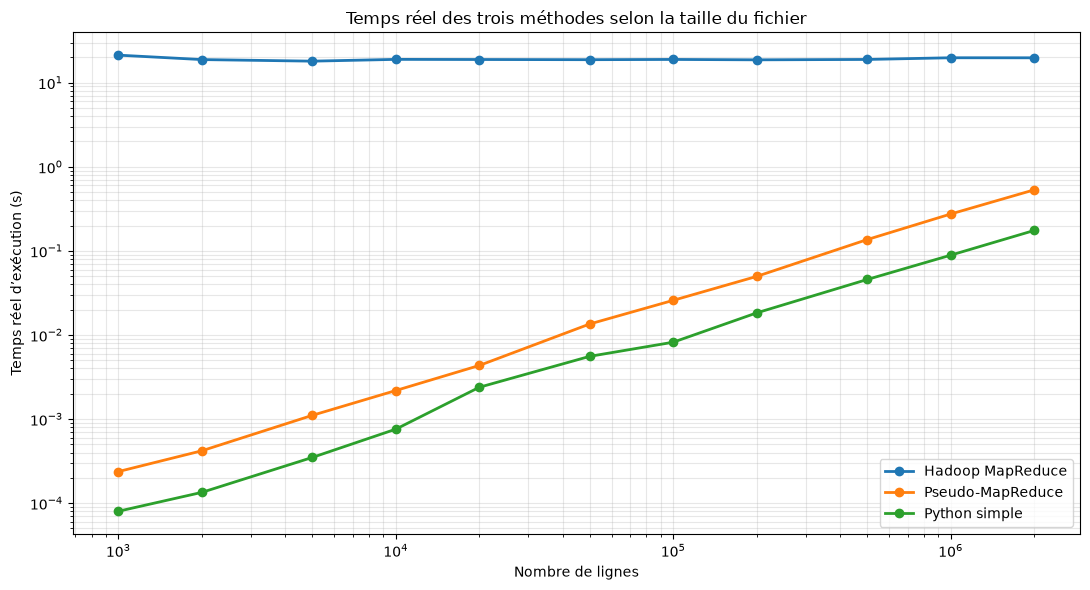

In [10]:
plt.figure(figsize=(11, 6))
for methode, groupe in resultats.groupby('méthode'):
    plt.plot(groupe['lignes'], groupe['temps_s'], marker='o', linewidth=2, label=methode)
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Nombre de lignes')
plt.ylabel('Temps réel d’exécution (s)')
plt.title('Temps réel des trois méthodes selon la taille du fichier')
plt.grid(True, which='both', alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## Conclusion à compléter après exécution

Sur de petits fichiers, Python simple est généralement le plus rapide car il a très peu de surcharge. Le pseudo-MapReduce ajoute les listes intermédiaires et le regroupement, donc il est souvent un peu plus lent, tout en illustrant clairement le modèle Map/Shuffle/Reduce. Hadoop introduit une latence de démarrage importante sur un fichier local ; son intérêt apparaît surtout pour de très gros volumes et un vrai cluster distribué.

La conclusion finale doit être basée sur les temps mesurés et le graphique produits par ce notebook.